In [1]:
#pip install scikeras

In [2]:
#IMPORTING LIBRARIES
#Evaluation library
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
#DeepLearning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
#scikit-learn wrapper for keras
from scikeras.wrappers import KerasClassifier


In [3]:
(x_train_digit, y_train_digit), (x_test_digit, y_test_digit) = mnist.load_data()

print("Training images: ", x_train_digit.shape)
print("Training labels: ", y_train_digit.shape)
print("Testing images: ", x_test_digit.shape)
print("Testing labels: ", y_test_digit.shape)

Training images:  (60000, 28, 28)
Training labels:  (60000,)
Testing images:  (10000, 28, 28)
Testing labels:  (10000,)


In [4]:
x_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [5]:
y_train_digit

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [6]:
x_train_digit[1]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  51, 159, 253, 159,  50,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  48, 238, 252, 252, 252, 237,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

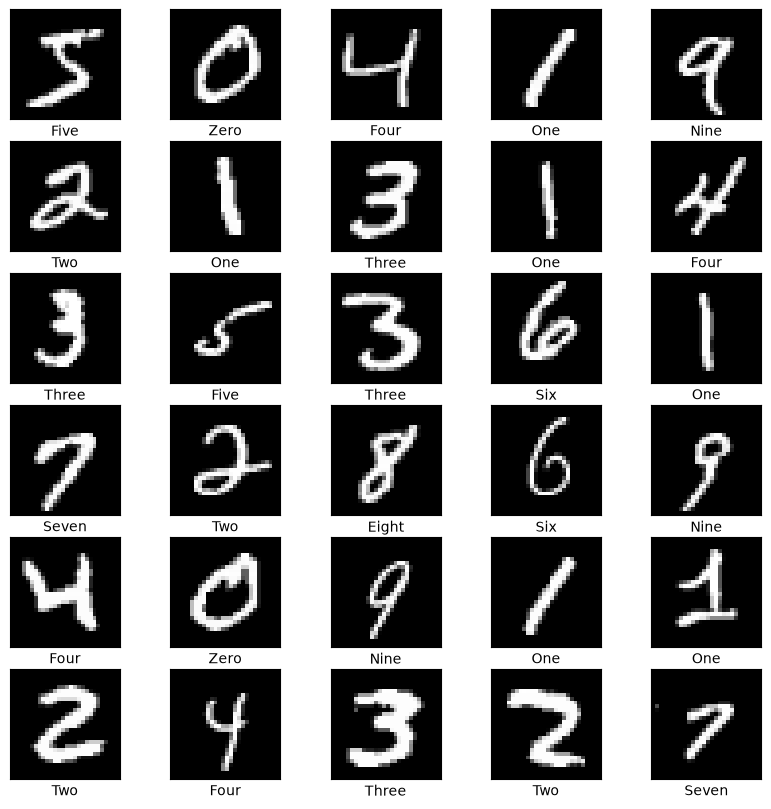

In [7]:
import matplotlib.pyplot as plt
#names of numbers in dataset
col_names = [
    'Zero','One', 'Two', 'Three', 'Four', 
    'Five', 'Six', 'Seven', 'Eight', 'Nine'
]

#Visualizing the digits
plt.figure(figsize=(10,10))
for i in range(30):
    plt.subplot(6,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_train_digit[i], cmap='gray')
    plt.xlabel(col_names[y_train_digit[i]])
plt.show()

In [8]:
x_train_digit.shape

(60000, 28, 28)

In [9]:
x_test_digit.shape

(10000, 28, 28)

In [10]:
x_train_digit = x_train_digit.reshape(60000,784)
x_test_digit = x_test_digit.reshape(10000,784)


In [11]:
x_train_digit.shape

(60000, 784)

In [12]:
x_train_digit

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(60000, 784), dtype=uint8)

In [13]:
y_train_digit.shape

(60000,)

In [14]:
#Encoding Digit minist labels
y_train_digit = to_categorical(y_train_digit, num_classes=10)
y_test_digit = to_categorical(y_test_digit, num_classes=10)

In [15]:
y_train_digit.shape

(60000, 10)

In [16]:
y_train_digit

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(60000, 10))

In [17]:
y_test_digit

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

In [18]:
#Creating base neural network
model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=(784,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='sigmoid'),
])

C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
#Compiling the model
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=['accuracy']
)

In [20]:
#Training the data
history = model.fit(
    x_train_digit,
    y_train_digit,
    batch_size=100,
    epochs=10,
    validation_data=(x_test_digit, y_test_digit)
)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.7633 - loss: 1.2925 - val_accuracy: 0.8580 - val_loss: 0.3282
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8759 - loss: 0.2723 - val_accuracy: 0.8768 - val_loss: 0.2464
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8951 - loss: 0.1861 - val_accuracy: 0.9085 - val_loss: 0.2101
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9091 - loss: 0.1446 - val_accuracy: 0.9216 - val_loss: 0.2122
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9180 - loss: 0.1213 - val_accuracy: 0.9097 - val_loss: 0.1584
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9145 - loss: 0.1099 - val_accuracy: 0.8955 - val_loss: 0.1687
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9139 - loss: 0.1004 - val_accuracy: 0.8948 - val_loss: 0.1488
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9177 - loss: 0.0918 - val_accurac

In [21]:
#predicting the labels-DIGIT
y_predict = model.predict(x_test_digit)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [22]:
y_predict

array([[2.8531725e-02, 9.9911034e-01, 9.9962831e-01, ..., 1.0000000e+00,
        9.9931735e-01, 9.9987423e-01],
       [1.5241685e-05, 3.0029907e-03, 9.9999899e-01, ..., 8.2660280e-04,
        1.8830721e-03, 1.5041932e-06],
       [3.7898745e-02, 9.9999863e-01, 9.2410237e-01, ..., 3.1843883e-01,
        1.2306859e-02, 3.5225829e-01],
       ...,
       [5.9019211e-08, 9.9987155e-01, 1.3107365e-01, ..., 9.9998170e-01,
        1.2911860e-03, 9.9997121e-01],
       [5.1399624e-01, 7.6301163e-04, 5.7641172e-01, ..., 1.2047803e-03,
        9.1265905e-01, 1.0914872e-01],
       [9.9995989e-01, 1.3716055e-07, 9.9999911e-01, ..., 9.9993634e-01,
        7.8348118e-01, 1.2143613e-05]], shape=(10000, 10), dtype=float32)

In [23]:
y_predict[0]

array([2.8531725e-02, 9.9911034e-01, 9.9962831e-01, 9.7766685e-01,
       4.4671289e-04, 3.4324687e-02, 5.6483562e-04, 1.0000000e+00,
       9.9931735e-01, 9.9987423e-01], dtype=float32)

In [24]:
import numpy as np
y_predicts = np.argmax(y_predict, axis=1)

In [25]:
y_predicts[0]

np.int64(7)

In [26]:
y_test_digit_eval = np.argmax(y_test_digit, axis=1)

In [27]:
y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

<function matplotlib.pyplot.show(close=None, block=None)>

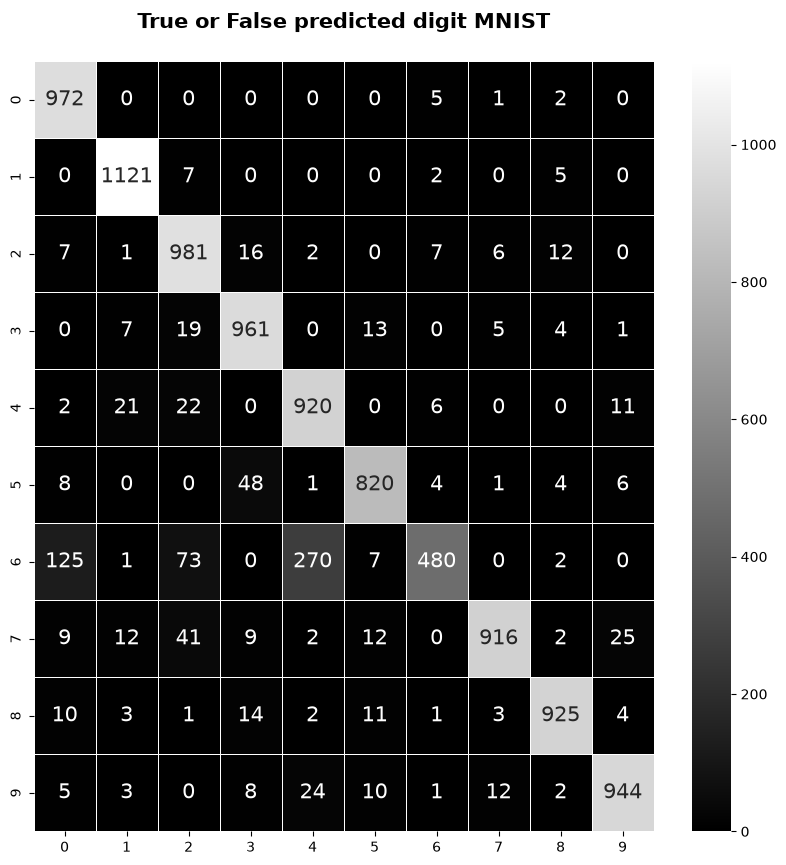

In [29]:
import seaborn as sns
con_mat = confusion_matrix(y_test_digit_eval, y_predicts)

plt.style.use('seaborn-v0_8-deep')
plt.figure(figsize=(10,10))

sns.heatmap(
    con_mat,
    annot=True,
    annot_kws={'size': 15},
    linewidths=0.5,
    fmt='d',
    cmap='gray'
)

plt.title(
    'True or False predicted digit MNIST\n',
    fontweight='bold',
    fontsize=15
)
plt.show

In [30]:
from sklearn.metrics import classification_report
print(classification_report(y_test_digit_eval, y_predicts))

              precision    recall  f1-score   support

           0       0.85      0.99      0.92       980
           1       0.96      0.99      0.97      1135
           2       0.86      0.95      0.90      1032
           3       0.91      0.95      0.93      1010
           4       0.75      0.94      0.84       982
           5       0.94      0.92      0.93       892
           6       0.95      0.50      0.66       958
           7       0.97      0.89      0.93      1028
           8       0.97      0.95      0.96       974
           9       0.95      0.94      0.94      1009

    accuracy                           0.90     10000
   macro avg       0.91      0.90      0.90     10000
weighted avg       0.91      0.90      0.90     10000



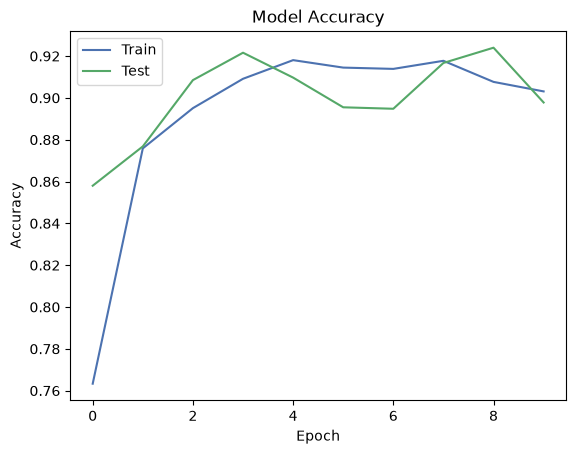

In [31]:
#summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')

plt.legend(['Train', 'Test'], loc='best')
plt.show()

In [32]:
col_names

['Zero',
 'One',
 'Two',
 'Three',
 'Four',
 'Five',
 'Six',
 'Seven',
 'Eight',
 'Nine']

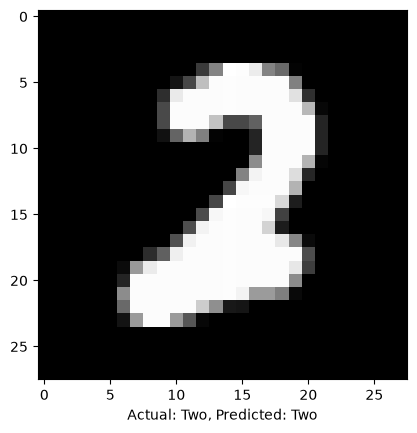

In [33]:
index = 199
plt.imshow(x_test_digit[index].reshape(28,28), cmap='gray')

actual = y_test_digit_eval[index]
predicted = y_predicts[index]

plt.xlabel(
    "Actual: {}, Predicted: {}".format(
        col_names[int(actual)],
        col_names[int(predicted)]
    )
)
plt.show()